# 03 - Random Forest

Train, evaluate và tuning Random Forest trên train/test split dùng chung. Random Forest không cần scaling.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

from src.preprocessing import prepare_data
from src.random_forest import PARAM_DISTRIBUTIONS, feature_importance, train_random_forest, tune_random_forest
from src.evaluation import evaluate_model, plot_confusion_matrix, print_report, save_figure, save_metrics

X_train, X_test, y_train, y_test = prepare_data()
print(X_train.shape, X_test.shape)

(69300, 32) (17325, 32)


## 1. Random Forest baseline

In [2]:
rf_base = train_random_forest(X_train, y_train)
rf_base_metrics = evaluate_model(rf_base, X_test, y_test, "Random Forest", "baseline")
print_report(rf_base, X_test, y_test)
rf_base_metrics

              precision    recall  f1-score   support

Not canceled     0.8611    0.9251    0.8919     12530
    Canceled     0.7570    0.6100    0.6756      4795

    accuracy                         0.8379     17325
   macro avg     0.8090    0.7675    0.7838     17325
weighted avg     0.8323    0.8379    0.8321     17325



{'model': 'Random Forest',
 'stage': 'baseline',
 'accuracy': 0.8378643578643579,
 'precision': 0.7569875776397516,
 'recall': 0.6100104275286757,
 'f1': 0.675597644069754,
 'roc_auc': 0.8903567746064295}

## 2. Tuning (`n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features`)

RandomizedSearchCV 12 tổ hợp, 3-fold trên tập train, tối ưu F1. Tập test không dùng khi tuning.

In [3]:
PARAM_DISTRIBUTIONS

{'model__n_estimators': [100, 200, 300],
 'model__max_depth': [None, 20, 30, 40],
 'model__min_samples_split': [2, 5, 10],
 'model__min_samples_leaf': [1, 2, 4],
 'model__max_features': ['sqrt', 0.3]}

In [4]:
rf_tuned, rf_params, rf_cv = tune_random_forest(X_train, y_train)
print("Best params:", rf_params, "CV F1:", round(rf_cv, 4))
rf_tuned_metrics = evaluate_model(rf_tuned, X_test, y_test, "Random Forest", "tuned")
print_report(rf_tuned, X_test, y_test)
rf_tuned_metrics

Best params: {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.3, 'model__max_depth': 30} CV F1: 0.67


              precision    recall  f1-score   support

Not canceled     0.8662    0.9169    0.8909     12530
    Canceled     0.7437    0.6300    0.6822      4795

    accuracy                         0.8375     17325
   macro avg     0.8050    0.7735    0.7865     17325
weighted avg     0.8323    0.8375    0.8331     17325



{'model': 'Random Forest',
 'stage': 'tuned',
 'accuracy': 0.8375180375180376,
 'precision': 0.7437223042836041,
 'recall': 0.6300312825860271,
 'f1': 0.6821722931015016,
 'roc_auc': 0.8960663500404035}

In [5]:
pd.DataFrame([rf_base_metrics, rf_tuned_metrics])

,model,stage,accuracy,precision,recall,f1,roc_auc
0,Random Forest,baseline,0.837864,0.756988,0.610010,0.675598,0.890357
1,Random Forest,tuned,0.837518,0.743722,0.630031,0.682172,0.896066


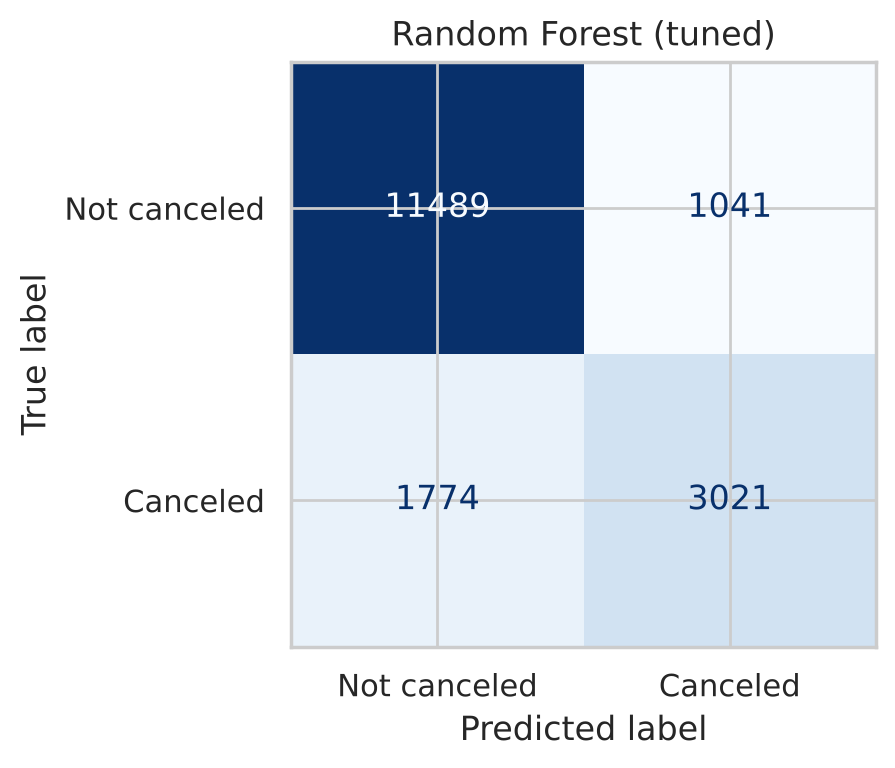

In [6]:
plot_confusion_matrix(rf_tuned, X_test, y_test, "Random Forest (tuned)", "confusion_matrix_rf.png")
plt.show()

## 3. Feature importance

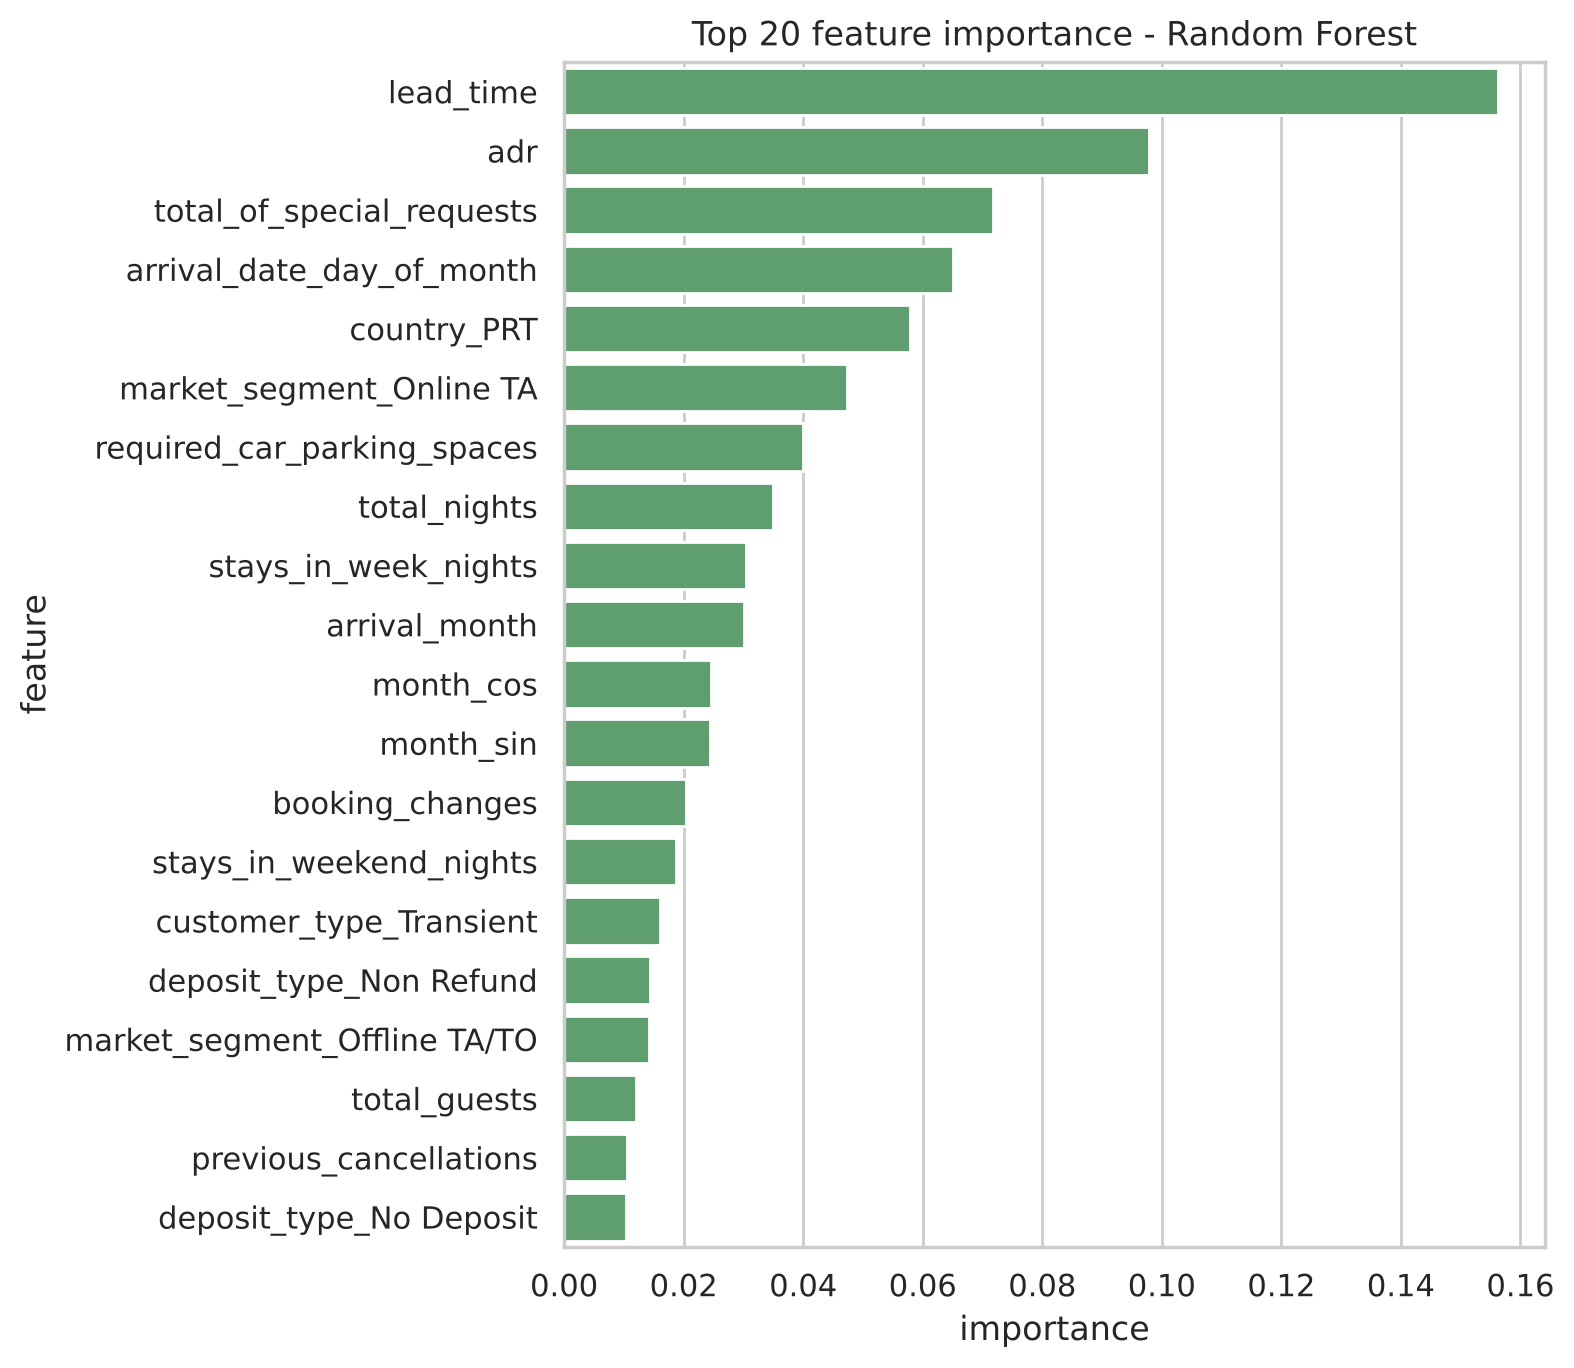

In [7]:
importance = feature_importance(rf_tuned, top_n=20)
fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(data=importance, y="feature", x="importance", ax=ax, color="#55A868")
ax.set_title("Top 20 feature importance - Random Forest")
save_figure(fig, "rf_feature_importance.png")
plt.show()

## 4. Lưu kết quả

In [8]:
table = save_metrics([rf_base_metrics, rf_tuned_metrics])
joblib.dump(rf_tuned, MODELS_DIR / "rf_tuned.joblib")
table

,model,stage,accuracy,precision,recall,f1,roc_auc
0,Naive Bayes,baseline,0.5431,0.3632,0.8638,0.5114,0.7445
1,Naive Bayes,tuned,0.6308,0.4164,0.8319,0.5550,0.7635
2,SVM,baseline,0.8098,0.7429,0.4784,0.5820,0.8559
3,SVM,tuned,0.8137,0.7095,0.5533,0.6217,0.8587
4,Random Forest,baseline,0.8379,0.7570,0.6100,0.6756,0.8904
5,Random Forest,tuned,0.8375,0.7437,0.6300,0.6822,0.8961


**Nhận xét:** `lead_time`, `adr`, `total_of_special_requests`, `country_PRT`, `market_segment_Online TA` và `required_car_parking_spaces` là các đặc trưng quan trọng nhất, khớp với phân tích EDA. Tuning cải thiện recall, F1 và ROC-AUC so với baseline.